<a href="https://colab.research.google.com/github/anupbagale/Image_Processing/blob/main/notebooks/05_noise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Noise

This notebook adds three common kinds of noise to an image and then tries two simple filters to
remove them.

| Noise | Model | Typical cause |
|---|---|---|
| Salt and pepper | random pixels set to 0 or 255 | bit errors, dead pixels |
| Gaussian | $g = f + n$, with $n \sim \mathcal{N}(0, \sigma^2)$ | sensor and electronic noise |
| Speckle | $g = f + f \cdot n$, with $n \sim \mathcal{N}(0, \sigma^2)$ | ultrasound and radar images |

Gaussian noise is added to every pixel by the same amount on average. Speckle noise is
multiplicative, so it is stronger in bright areas.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams["image.cmap"] = "gray"

rng = np.random.default_rng(0)   # fixed seed so the results are the same every run

In [2]:
image = data.camera()

## Adding the noise

In [3]:
def salt_and_pepper(img, amount=0.05):
    noisy = img.copy()
    mask = rng.random(img.shape)
    noisy[mask < amount / 2] = 0              # pepper
    noisy[mask > 1 - amount / 2] = 255        # salt
    return noisy


def gaussian_noise(img, sigma=25):
    noise = rng.normal(0, sigma, img.shape)
    return np.clip(img + noise, 0, 255).astype(np.uint8)


def speckle_noise(img, sigma=0.2):
    f = img / 255.0
    noise = rng.normal(0, sigma, img.shape)
    return (np.clip(f + f * noise, 0, 1) * 255).astype(np.uint8)


noisy = {
    "salt and pepper (5%)": salt_and_pepper(image),
    "Gaussian (σ = 25)": gaussian_noise(image),
    "speckle (σ = 0.2)": speckle_noise(image),
}

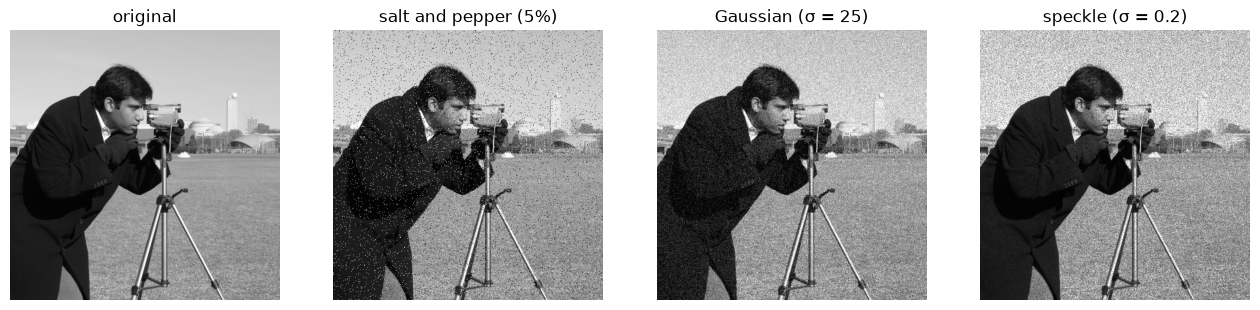

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(16, 4.5))
ax[0].imshow(image); ax[0].set_title("original")
for a, (name, img) in zip(ax[1:], noisy.items()):
    a.imshow(img)
    a.set_title(name)
for a in ax:
    a.axis("off")
plt.show()

Zooming in makes the difference between the three easier to see:

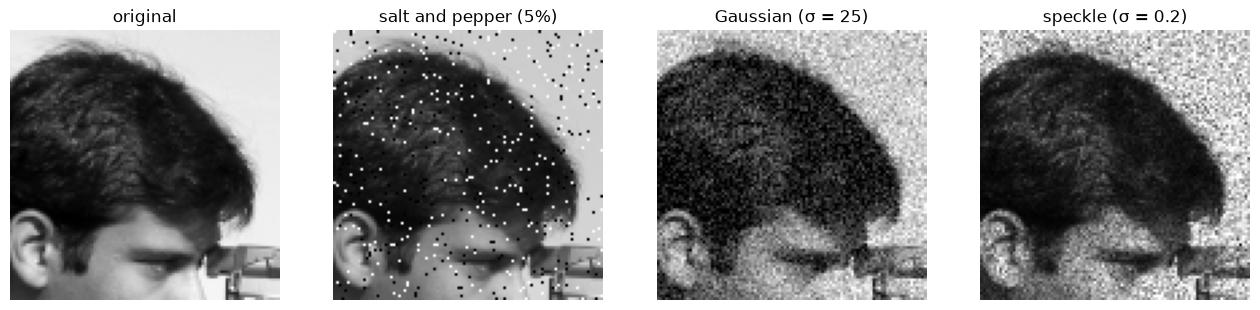

In [5]:
fig, ax = plt.subplots(1, 4, figsize=(16, 4.5))
ax[0].imshow(image[60:160, 180:280]); ax[0].set_title("original")
for a, (name, img) in zip(ax[1:], noisy.items()):
    a.imshow(img[60:160, 180:280])
    a.set_title(name)
for a in ax:
    a.axis("off")
plt.show()

## Measuring the damage

The peak signal-to-noise ratio (PSNR) compares a noisy image $g$ with the original $f$:

$$\text{PSNR} = 10 \log_{10} \frac{255^2}{\text{MSE}}, \qquad \text{MSE} = \frac{1}{N}\sum (f - g)^2$$

It is measured in decibels, and higher means closer to the original.

In [6]:
def psnr(original, other):
    mse = np.mean((original.astype(float) - other.astype(float)) ** 2)
    return 10 * np.log10(255 ** 2 / mse)


for name, img in noisy.items():
    print(f"{name:<22} PSNR = {psnr(image, img):5.2f} dB   (cv2.PSNR: {cv2.PSNR(image, img):5.2f})")

salt and pepper (5%)   PSNR = 17.75 dB   (cv2.PSNR: 17.75)
Gaussian (σ = 25)      PSNR = 20.58 dB   (cv2.PSNR: 20.58)
speckle (σ = 0.2)      PSNR = 19.20 dB   (cv2.PSNR: 19.20)


## Removing the noise

Two simple filters, both using a 5 x 5 window:

- a **median filter** replaces each pixel with the median of its neighbourhood
- a **Gaussian blur** replaces it with a weighted average

In [7]:
print(f"{'noise':<22} {'noisy':>8} {'median':>8} {'Gaussian':>9}")
filtered = {}
for name, img in noisy.items():
    med = cv2.medianBlur(img, 5)
    gau = cv2.GaussianBlur(img, (5, 5), 0)
    filtered[name] = (med, gau)
    print(f"{name:<22} {psnr(image, img):8.2f} {psnr(image, med):8.2f} {psnr(image, gau):9.2f}")

noise                     noisy   median  Gaussian
salt and pepper (5%)      17.75    27.87     25.67
Gaussian (σ = 25)         20.58    26.31     27.17
speckle (σ = 0.2)         19.20    25.75     26.62


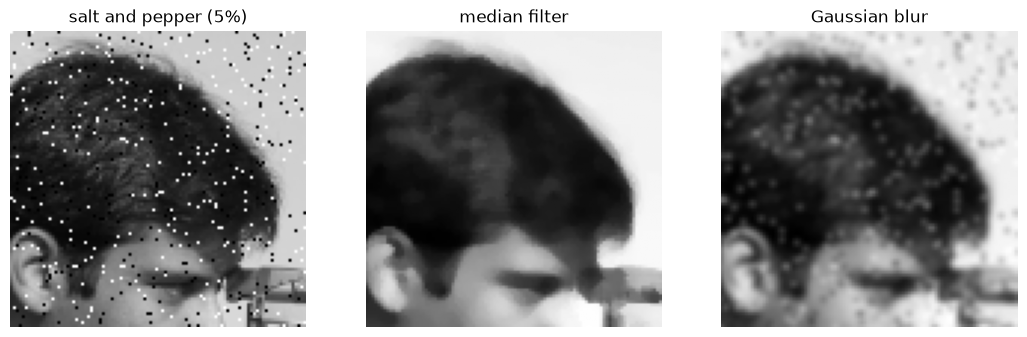

In [8]:
name = "salt and pepper (5%)"
med, gau = filtered[name]
fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
for a, img, title in zip(ax, [noisy[name], med, gau], [name, "median filter", "Gaussian blur"]):
    a.imshow(img[60:160, 180:280])
    a.set_title(title)
    a.axis("off")
plt.show()

The median filter removes salt and pepper noise almost completely, because a few extreme values
do not change the median of a window. A Gaussian blur only spreads those extreme values into
grey smudges. For Gaussian and speckle noise the Gaussian blur does a little better, because
averaging out small random changes is exactly what that kind of noise needs.